In [1]:
import numpy as np
import pandas as pd
import mne
import h5py
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from nilearn.plotting import plot_markers
from mne_bids import BIDSPath

from himalaya.backend import set_backend, get_backend
from himalaya.ridge import RidgeCV
from himalaya.scoring import correlation_score

from sklearn.model_selection import KFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
import numpy as np
import pandas as pd
import re
import mne
import numpy as np
from mne_bids import BIDSPath
from nilearn import datasets, image
from scipy.spatial import KDTree
from collections import Counter

import numpy as np
import pandas as pd
from scipy import stats
from statsmodels.stats.multitest import fdrcorrection
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
import numpy as np
import pandas as pd
from transformers import GPT2Tokenizer
import mne
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from mne_bids import BIDSPath
from scipy.signal import convolve
from scipy.stats import zscore
from statsmodels.stats.multitest import fdrcorrection

import os
import mne
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from mne_bids import BIDSPath
from himalaya.backend import get_backend
from himalaya.scoring import correlation_score
from sklearn.model_selection import KFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from himalaya.ridge import RidgeCV
from scipy import stats
from statsmodels.stats.multitest import fdrcorrection

/opt/anaconda3/envs/aineuro/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


# Creating the Incorrect and Correct dataframes

In [2]:
transcript_path = "stimuli/podcast_transcript.csv"

df = pd.read_csv(transcript_path)
df.head(20)

,word,start,end
0,Act,3.710,3.790
1,"one,",3.990,4.190
2,monkey,4.651,4.931
3,in,4.951,5.011
4,the,5.051,5.111
5,middle.,5.151,5.391
6,So,6.592,6.732
7,there's,6.752,6.912
8,some,6.892,7.052
9,places,7.072,7.342


In [3]:
glove_path = 'glove.6B.50d.txt'
#create the glove model based on our glove file 
def load_glove_to_dict(file_path):
    glove_dict = {}
    print(f"Loading {file_path}...")

    with open(file_path, 'r', encoding='utf-8') as f:
        for line in f:
            # Each line looks like: word 0.123 0.456 ...
            values = line.split()
            word = values[0]
            # Convert the numbers into a numpy array
            vector = np.asarray(values[1:], dtype='float32')
            glove_dict[word] = vector

    print(f"Done! {len(glove_dict)} words loaded.")
    return glove_dict


# Load the model
glove_model = load_glove_to_dict(glove_path)

# Build GloVe embeddings for the transcript 

def clean_word(w):
    """Better clean up: Lowercase + normalize apostrophes + strip punctuation."""
    w = str(w).lower()
    # Normalize curly apostrophes to straight ones for GloVe compatibility
    w = re.sub(r"[’‘’ʻ]", "'", w)
    # Strip punctuation but keep internal apostrophes (don't strip ')
    return w.strip(" .,!?;:\"()-[]")

# Update the dataframe with the better cleanup
df["word_clean"] = df["word"].apply(clean_word)

# Define words that should be excluded as fillers 
EXCLUDE_FILLERS = {'ch', 'hm', 'mhm', 'mm','uh', 'um'}

# Assign embeddings, track OOV words 
def get_glove_vector(w):
    if w in EXCLUDE_FILLERS or w not in glove_model:
        return None
    return glove_model[w]

# Apply the function to create a new column
df["glove_embedding"] = df["word_clean"].apply(get_glove_vector)

# Filter the dataframe to remove rows where no embedding was found 
df_glove = df.dropna(subset=["glove_embedding"]).copy()

# X_glove matrix for the encoding model: This stacks the arrays from the column into a single numpy matrix
X_glove = np.stack(df_glove["glove_embedding"].values).astype("float32")

# Track OOV 
oov_count = len(df) - len(df_glove)

print("=" * 50)
print(f"Total words in transcript : {len(df)}")
print(f"Words WITH GloVe embedding: {len(df_glove)}")
print(f"Words WITHOUT (OOV/Fill)  : {oov_count}")
print(f"X_glove shape             : {X_glove.shape}")
print("=" * 50)

# Show the first few rows (embedding array in new column)
df_glove.head(8)

Loading glove.6B.50d.txt...
Done! 400000 words loaded.
Total words in transcript : 5136
Words WITH GloVe embedding: 4867
Words WITHOUT (OOV/Fill)  : 269
X_glove shape             : (4867, 50)


,word,start,end,word_clean,glove_embedding
0,Act,3.710,3.790,act,"[-0.60647, -0.65705, -1.1819, -0.61002, -0.197..."
1,"one,",3.990,4.190,one,"[0.31474, 0.41662, 0.1348, 0.15854, 0.88812, 0..."
2,monkey,4.651,4.931,monkey,"[0.28704, -0.60904, -0.74821, 0.17686, 0.92118..."
3,in,4.951,5.011,in,"[0.33042, 0.24995, -0.60874, 0.10923, 0.036372..."
4,the,5.051,5.111,the,"[0.418, 0.24968, -0.41242, 0.1217, 0.34527, -0..."
5,middle.,5.151,5.391,middle,"[-0.15502, 1.0436, -0.22143, -0.89604, 0.49455..."
6,So,6.592,6.732,so,"[0.60308, -0.32024, 0.088857, -0.55176, 0.5318..."
8,some,6.892,7.052,some,"[0.92871, -0.10834, 0.21497, -0.50237, 0.10379..."


In [4]:

transcript_path = "stimuli/gpt2-xl/transcript.tsv"
df_gpt = pd.read_csv(transcript_path, sep="\t", index_col=0)


In [5]:
#turning tokens into words, if word is more than one token, keeping the first tokens ranks (since that the first thing gpt is predicting anyways)
#also keeping the first tokens true_probability, entropy, top_prediction, ect.
#if top prediction is a half-word and that not avaliable in vocbulary is it excluded
df_gpt = (df_gpt
          .groupby('word_idx', sort=True)
          .first()
          .reset_index())

In [6]:

# Apply cleaning to the GPT dataframe/ words (already turned tokens into words)
df_gpt["word_clean"] = df_gpt["word"].apply(clean_word)

# Filter and assign GloVe embeddings
# This creates the additional column and filters rows in one pass
embeddings = []
valid_indices = []

for idx, row in df_gpt.iterrows():
    w = row["word_clean"]
    # Keep only if NOT a filler AND exists in GloVe vocabulary
    if w not in EXCLUDE_FILLERS and w in glove_model:
        embeddings.append(glove_model[w])
        valid_indices.append(idx)

# Create the final filtered dataframe with all original GPT columns + embeddings
df_gpt_glove = df_gpt.loc[valid_indices].copy()
df_gpt_glove["glove_embedding"] = embeddings

# Verification 
print(f"Original GPT words: {len(df_gpt)}")
print(f"Final aligned rows: {len(df_gpt_glove)}")
# The paper reports 4,843 words for the full GloVe analysis (i have 4867: different processing methods)

Original GPT words: 5136
Final aligned rows: 4867


In [7]:
# Create the 'correct' dataframe (rank 1, 2, 3, or 4) <= 4 to include the top 4 ranks.
correct = df_gpt_glove[df_gpt_glove['rank'] <= 4].copy()

# Create the 'incorrect' dataframe (rank 5 and above)
incorrect = df_gpt_glove[df_gpt_glove['rank'] > 4].copy()

# Verification
print(f"Total aligned rows: {len(df_gpt_glove)}")
print(f"Correct (Rank <= 4) rows: {len(correct)}")
print(f"Incorrect (Rank > 4) rows: {len(incorrect)}")

# Sanity check to ensure no rows were lost
assert len(correct) + len(incorrect) == len(df_gpt_glove)

Total aligned rows: 4867
Correct (Rank <= 4) rows: 2531
Incorrect (Rank > 4) rows: 2336


In [8]:

# Initialize the tokenizer (use 'gpt2-xl')
tokenizer = GPT2Tokenizer.from_pretrained('gpt2-xl')

# Function to convert token ID to a clean word string
def id_to_word(token_id):
    # Decode the ID
    word = tokenizer.decode([token_id])
    # GPT-2 tokens often have a preceding space (indicated by 'Ġ' in some viewers)
    # strip whitespace to get the "natural" word for display/analysis
    return word.strip()

# Apply to the incorrect dataframe
# 'top_pred' contains integer token ID
incorrect['top_pred'] = incorrect['top_pred'].apply(id_to_word)

In [9]:
# Clean the top_pred_word (the predicited word turned into token)
incorrect["top_pred"] = incorrect["top_pred"].apply(clean_word)

# Filter and extract embeddings for the predictions
pred_embeddings = []
valid_pred_indices = []

for idx, row in incorrect.iterrows():
    w_pred = row["top_pred"]
    
    # Apply the same rules: Not a filler AND must exist in the GloVe model
    #keeping excluded fillers for consistency
    if w_pred not in EXCLUDE_FILLERS and w_pred in glove_model:
        pred_embeddings.append(glove_model[w_pred])
        valid_pred_indices.append(idx)

# Create the final filtered incorrect dataframe
# This keeps only rows where BOTH the actual word and the predicted word have GloVe embeddings
incorrect_filtered = incorrect.loc[valid_pred_indices].copy()

# Add the new column for the prediction's embedding
incorrect_filtered["glove_embedding_prediction"] = pred_embeddings

# Verification 
print(f"Rows in incorrect before prediction filtering: {len(incorrect)}")
print(f"Rows in incorrect after prediction filtering : {len(incorrect_filtered)}")

# Check a sample to see the alignment
print("\nSample of Incorrect Mismatches (Actual vs Predicted):")
print(incorrect_filtered[['word', 'top_pred', 'rank']].head())

Rows in incorrect before prediction filtering: 2336
Rows in incorrect after prediction filtering : 1978

Sample of Incorrect Mismatches (Actual vs Predicted):
       word top_pred  rank
1      one,        1    92
2    monkey    scene  4022
8      some        a    12
9    places       of   528
11  animals      you    53


In [10]:
correct.shape

(2531, 12)

In [41]:
incorrect_filtered.shape

(1978, 13)

# Figure 5 A)

In [ ]:
bids_root = "ADD your BIDS dataset path here"

Total significant electrodes: 174
sub-02: no significant electrodes, skipping

sub-03: 41 significant electrodes
  41 channels after selection
  After z-score+smooth: mean=0.0000  std=0.5844  range=[-1.54, 10.51]


/var/folders/28/5h1f5z1n1sg6x_cxrjkyfgbh0000gn/T/ipykernel_6783/2225827504.py:79: RuntimeWarning: The events passed to the Epochs constructor are not chronologically ordered.
  epochs_correct = mne.Epochs(
/var/folders/28/5h1f5z1n1sg6x_cxrjkyfgbh0000gn/T/ipykernel_6783/2225827504.py:86: RuntimeWarning: The events passed to the Epochs constructor are not chronologically ordered.
  epochs_incorrect = mne.Epochs(


  Correct epochs:   2528
  Incorrect epochs: 1975

sub-04: 15 significant electrodes
  15 channels after selection
  After z-score+smooth: mean=0.0000  std=0.6277  range=[-1.67, 8.94]
  Correct epochs:   2528
  Incorrect epochs: 1975


/var/folders/28/5h1f5z1n1sg6x_cxrjkyfgbh0000gn/T/ipykernel_6783/2225827504.py:79: RuntimeWarning: The events passed to the Epochs constructor are not chronologically ordered.
  epochs_correct = mne.Epochs(
/var/folders/28/5h1f5z1n1sg6x_cxrjkyfgbh0000gn/T/ipykernel_6783/2225827504.py:86: RuntimeWarning: The events passed to the Epochs constructor are not chronologically ordered.
  epochs_incorrect = mne.Epochs(



sub-05: 3 significant electrodes
  3 channels after selection
  After z-score+smooth: mean=-0.0000  std=0.4861  range=[-1.34, 30.25]


...


sub-08: 16 significant electrodes
  16 channels after selection
  After z-score+smooth: mean=-0.0005  std=0.5448  range=[-1.69, 67.86]
  Correct epochs:   2528
  Incorrect epochs: 1975

sub-09: 55 significant electrodes


/var/folders/28/5h1f5z1n1sg6x_cxrjkyfgbh0000gn/T/ipykernel_6783/2225827504.py:79: RuntimeWarning: The events passed to the Epochs constructor are not chronologically ordered.
  epochs_correct = mne.Epochs(
/var/folders/28/5h1f5z1n1sg6x_cxrjkyfgbh0000gn/T/ipykernel_6783/2225827504.py:86: RuntimeWarning: The events passed to the Epochs constructor are not chronologically ordered.
  epochs_incorrect = mne.Epochs(


  55 channels after selection
  After z-score+smooth: mean=0.0000  std=0.6071  range=[-1.67, 30.44]


/var/folders/28/5h1f5z1n1sg6x_cxrjkyfgbh0000gn/T/ipykernel_6783/2225827504.py:79: RuntimeWarning: The events passed to the Epochs constructor are not chronologically ordered.
  epochs_correct = mne.Epochs(
/var/folders/28/5h1f5z1n1sg6x_cxrjkyfgbh0000gn/T/ipykernel_6783/2225827504.py:86: RuntimeWarning: The events passed to the Epochs constructor are not chronologically ordered.
  epochs_incorrect = mne.Epochs(


  Correct epochs:   2528
  Incorrect epochs: 1975

Total electrodes pooled: 174


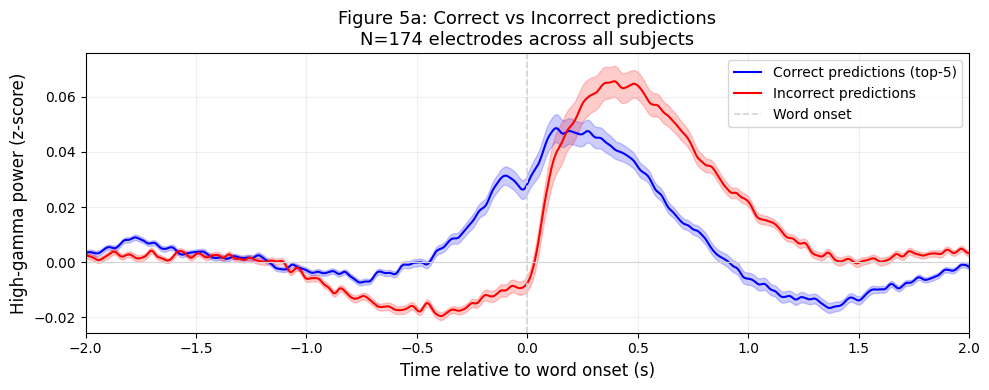

N correct words  : 2531
N incorrect words: 1978


In [31]:
# Helper functions
def hamming_smooth(data, sfreq, window_ms=50):
    """Smooth (n_channels, n_times) with zero-phase Hamming on continuous data."""
    n_samples = int(window_ms / 1000 * sfreq)
    if n_samples % 2 == 0:
        n_samples += 1
    win = np.hamming(n_samples)
    win /= win.sum()
    smoothed = np.zeros_like(data)
    for ch in range(data.shape[0]):
        fwd = convolve(data[ch], win, mode='same')
        smoothed[ch] = convolve(fwd[::-1], win, mode='same')[::-1]
    return smoothed

def make_events(df_words, sfreq):
    events = np.zeros((len(df_words), 3), dtype=int)
    events[:, 0] = (df_words['start'].values * sfreq).astype(int)
    return events

# Load significant electrodes
sig_elec_master = pd.read_csv("significant_electrodes_glove.csv")
sig_elec_master["subject"] = sig_elec_master["subject"].astype(str).str.zfill(2)
print(f"Total significant electrodes: {len(sig_elec_master)}")

subject_ids = ["02", "03", "04", "05", "06", "07", "08", "09"]
tmin, tmax  = -2.0, 2.0

all_evoked_correct   = []   # (n_sig_elec_this_sub, n_times) per subject
all_evoked_incorrect = []
times_final = None

for sid in subject_ids:

    # Check significant electrodes 
    sub_sig = sig_elec_master[sig_elec_master["subject"] == sid]
    if len(sub_sig) == 0:
        print(f"sub-{sid}: no significant electrodes, skipping")
        continue

    sig_indices = sub_sig["elec_idx"].values
    print(f"\nsub-{sid}: {len(sig_indices)} significant electrodes")

    # Load raw 
    file_path = BIDSPath(
        root=f"{bids_root}derivatives/ecogprep",
        subject=sid, task="podcast", datatype="ieeg",
        description="highgamma", suffix="ieeg", extension=".fif"
    )
    raw = mne.io.read_raw_fif(file_path.fpath, verbose=False, preload=True)

    # Left-hemisphere filter then pick significant electrodes 
    ch2loc    = {ch['ch_name']: ch['loc'][:3] for ch in raw.info['chs']}
    coords_mm = np.vstack([ch2loc[ch] for ch in raw.ch_names]) * 1000
    lh_mask   = coords_mm[:, 0] < 0
    raw = raw.copy().pick([ch for ch, k in zip(raw.ch_names, lh_mask) if k])
    raw = raw.copy().pick([raw.ch_names[i] for i in sig_indices])
    print(f"  {len(raw.ch_names)} channels after selection")

    sfreq = raw.info['sfreq']

    # Z-score then Hamming smooth on continuous signal 
    # Matching paper preprocessing order exactly
    raw_data = raw.get_data()                              # (n_elec, n_times)
    raw_data = zscore(raw_data, axis=1)                    # z-score per electrode
    raw_data = hamming_smooth(raw_data, sfreq, window_ms=50)  # smooth

    # Sanity check
    print(f"  After z-score+smooth: mean={raw_data.mean():.4f}  "
          f"std={raw_data.std():.4f}  "
          f"range=[{raw_data.min():.2f}, {raw_data.max():.2f}]")

    raw_processed = mne.io.RawArray(raw_data, raw.info, verbose=False)

    # Build events 
    events_correct   = make_events(correct,            sfreq)
    events_incorrect = make_events(incorrect_filtered, sfreq)

    # Epoch 
    epochs_correct = mne.Epochs(
        raw_processed, events_correct,
        tmin=tmin, tmax=tmax,
        baseline=None, proj=False,
        preload=True, event_repeated="merge",
        verbose=False
    )
    epochs_incorrect = mne.Epochs(
        raw_processed, events_incorrect,
        tmin=tmin, tmax=tmax,
        baseline=None, proj=False,
        preload=True, event_repeated="merge",
        verbose=False
    )

    print(f"  Correct epochs:   {len(epochs_correct)}")
    print(f"  Incorrect epochs: {len(epochs_incorrect)}")

    # Average across words → evoked per electrode (n_elec, n_times) 
    all_evoked_correct.append(epochs_correct.average().data)
    all_evoked_incorrect.append(epochs_incorrect.average().data)

    if times_final is None:
        times_final = epochs_correct.times   # save times from first subject

# Pool across all subjects along electrode axis 
pooled_correct   = np.concatenate(all_evoked_correct,   axis=0)  # (total_elec, n_times)
pooled_incorrect = np.concatenate(all_evoked_incorrect, axis=0)

n_elec = pooled_correct.shape[0]
print(f"\nTotal electrodes pooled: {n_elec}")

grand_avg_correct   = pooled_correct.mean(axis=0)
grand_avg_incorrect = pooled_incorrect.mean(axis=0)
se_correct          = pooled_correct.std(axis=0)   / np.sqrt(n_elec)
se_incorrect        = pooled_incorrect.std(axis=0) / np.sqrt(n_elec)

# Plot 
fig, ax = plt.subplots(figsize=(10, 4))

ax.plot(times_final, grand_avg_correct,
        color='blue', lw=1.5, label='Correct predictions (top-5)')
ax.plot(times_final, grand_avg_incorrect,
        color='red',  lw=1.5, label='Incorrect predictions')

ax.fill_between(times_final,
                grand_avg_correct - se_correct,
                grand_avg_correct + se_correct,
                color='blue', alpha=0.2)
ax.fill_between(times_final,
                grand_avg_incorrect - se_incorrect,
                grand_avg_incorrect + se_incorrect,
                color='red', alpha=0.2)

ax.axvline(0,  color='lightgray', ls='--', lw=1.2, label='Word onset')
ax.axhline(0,  color='lightgray', ls='-',  lw=0.8)
ax.set_xlabel("Time relative to word onset (s)", fontsize=12)
ax.set_ylabel("High-gamma power (z-score)", fontsize=12)
ax.set_title(f"Figure 5a: Correct vs Incorrect predictions\n"
             f"N={n_elec} electrodes across all subjects", fontsize=13)
ax.set_xlim(-2, 2)
ax.legend(fontsize=10)
ax.grid(True, alpha=0.2)
plt.tight_layout()
plt.savefig("fig5a_correct_vs_incorrect.png", dpi=150, bbox_inches='tight')
plt.show()

print(f"N correct words  : {len(correct)}")
print(f"N incorrect words: {len(incorrect_filtered)}")

In [56]:
#Making plot better/ following the paper and doing stastical testing just like in figure 4 A:

def run_significance_test(data, n_perms=5000):
    """
    Performs a one-tailed permutation test (data > 0) per timepoint.
    data shape: (n_electrodes, n_times)
    """
    n_elec_total, n_times = data.shape
    actual_mean = data.mean(axis=0)
    
    # Pre-calculate the % of electrodes that are positive at each lag
    pct_pos = (data > 0).mean(axis=0)

    rng = np.random.default_rng(seed=0)
    # Generate random sign flips: shape (n_perms, n_elec, 1)
    signs = rng.choice(np.array([-1, 1], dtype=np.float32), 
                       size=(n_perms, n_elec_total, 1))

    # Apply flips to build null distribution of the grand mean
    null_dist = (signs * data[np.newaxis, :, :]).mean(axis=1)

    # Calculate p-values (proportion of null means >= actual mean)
    p_vals = np.array([(null_dist[:, t] >= actual_mean[t]).mean() for t in range(n_times)])
    
    # FDR Correction
    sig_fdr, _ = fdrcorrection(p_vals, alpha=0.01)
    
    # Final criteria: Significant mean AND 76% majority threshold
    sig_final = sig_fdr & (pct_pos >= 0.76)
    
    return sig_final

# Run for both conditions
sig_correct = run_significance_test(pooled_correct)
sig_incorrect = run_significance_test(pooled_incorrect)

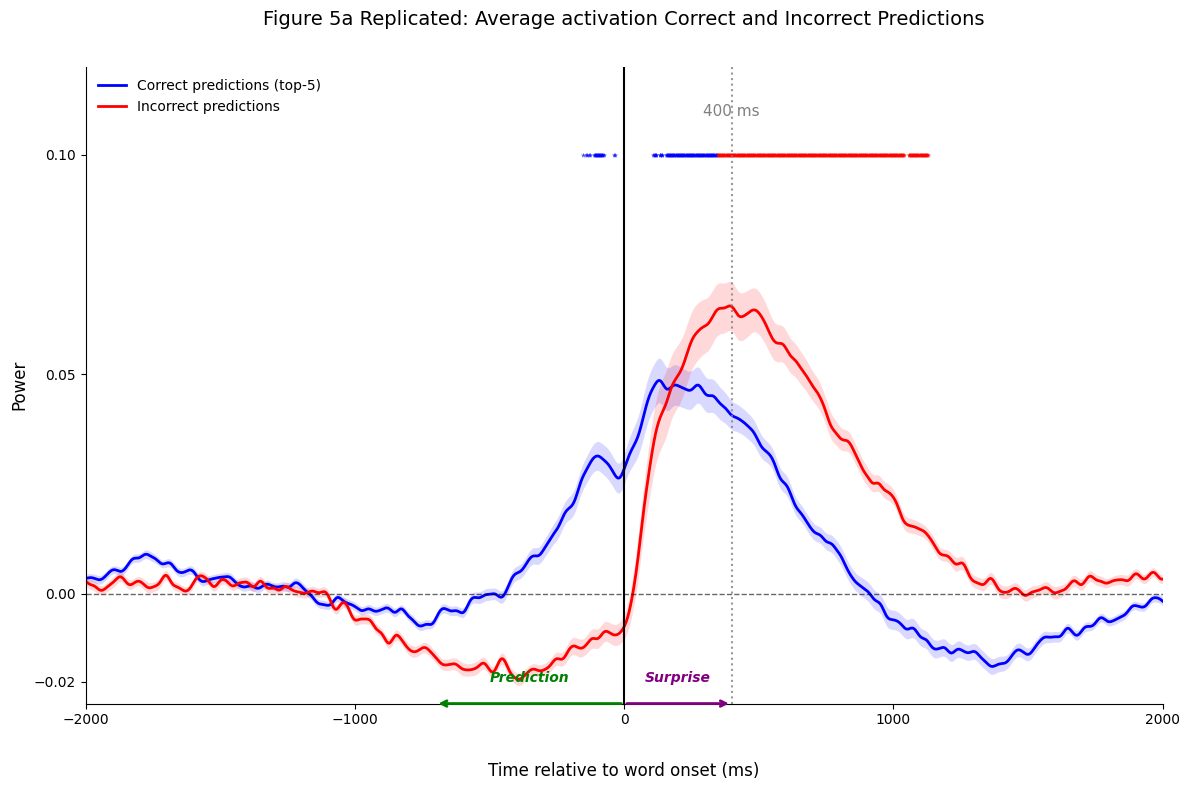

In [59]:
#PLOTTING
def make_replicated_plot(sig_corr, sig_incorr):
    times_ms = times_final * 1000 
    
    # Averages and SEM
    mean_c = pooled_correct.mean(axis=0);   se_c = pooled_correct.std(axis=0)/np.sqrt(n_elec)
    mean_i = pooled_incorrect.mean(axis=0); se_i = pooled_incorrect.std(axis=0)/np.sqrt(n_elec)

    # OVERLAP & TIME FILTERING LOGIC 
    sig_corr_clean = sig_corr & ~sig_incorr
    sig_corr_clean &= (times_ms >= -1000)

    fig, ax = plt.subplots(figsize=(12, 8))

    # Plot Curves
    ax.fill_between(times_ms, mean_c - se_c, mean_c + se_c, color='blue', alpha=0.15, lw=0)
    ax.plot(times_ms, mean_c, color='blue', lw=2, label='Correct predictions (top-5)')

    ax.fill_between(times_ms, mean_i - se_i, mean_i + se_i, color='red', alpha=0.15, lw=0)
    ax.plot(times_ms, mean_i, color='red', lw=2, label='Incorrect predictions')

    # AXIS LIMITS 
    y_min = -0.025  
    y_max = 0.12    
    ax.set_ylim(y_min, y_max)
    
    # SIGNIFICANCE ON SAME HORIZONTAL LINE (y=0.1) 
    star_y = 0.1
    if sig_corr_clean.any():
        ax.scatter(times_ms[sig_corr_clean], np.full(sig_corr_clean.sum(), star_y),
                   marker="*", s=15, color="blue", alpha=0.7, linewidths=0)
    if sig_incorr.any():
        ax.scatter(times_ms[sig_incorr], np.full(sig_incorr.sum(), star_y),
                   marker="*", s=15, color="red", alpha=0.7, linewidths=0)

    # "400 ms" LABEL ABOVE STARS 
    ax.text(400, star_y + 0.008, "400 ms", ha='center', va='bottom', 
            fontsize=11, color='grey', fontweight='normal')

    # Dotted Baseline at y=0
    ax.axhline(0, color="black", lw=1.0, ls="--", alpha=0.6)
    
    # Dotted line at 400 ms
    ax.axvline(400, color="grey", lw=1.5, ls=":", alpha=0.8)
    
    # Word onset Line
    ax.axvline(0, color="black", lw=1.5)

    # Floor spine and styling
    ax.spines['bottom'].set_position(('data', y_min))
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    
    # Force y-ticks
    ax.set_yticks([-0.02, 0, 0.05, 0.1])

    # --- ARROWS ---
    # Green Prediction Arrow
    ax.annotate('', xy=(-700, y_min), xytext=(0, y_min),
                arrowprops=dict(arrowstyle='->', color='green', lw=2))
    ax.text(-350, y_min + 0.005, "Prediction", color="green", style="italic", ha="center", fontweight='bold')

    # Purple Surprise Arrow (0 to 400 ms)
    ax.annotate('', xy=(400, y_min), xytext=(0, y_min),
                arrowprops=dict(arrowstyle='->', color='purple', lw=2))
    ax.text(200, y_min + 0.005, "Surprise", color="purple", style="italic", ha="center", fontweight='bold')

    # General Styling
    ax.set_xlim(-2000, 2000)
    # Removed 400 from xticks
    ax.set_xticks([-2000, -1000, 0, 1000, 2000])
    
    ax.set_xlabel("Time relative to word onset (ms)", fontsize=12, labelpad=25)
    ax.set_ylabel("Power", fontsize=12) 
    
    # TITLE 
    ax.set_title("Figure 5a Replicated: Average activation Correct and Incorrect Predictions", 
                 loc='center', fontsize=14, fontweight='normal', pad=30)

    plt.legend(loc="upper left", frameon=False)
    plt.tight_layout()
    
    # Save high quality
    plt.savefig("fig5a_final_replica.pdf", format='pdf', bbox_inches='tight')
    plt.show()

make_replicated_plot(sig_correct, sig_incorrect)

# Figure 4 B)

In [60]:
#We have our two dataframes:
print(correct.shape)
correct.head(2)
print(incorrect_filtered.shape)
incorrect_filtered.head(2)

(2531, 12)
(1978, 13)


,word_idx,word,start,end,hftoken,token_id,rank,true_prob,top_pred,entropy,word_clean,glove_embedding,glove_embedding_prediction
1,1,"one,",3.990,4.190,Ġone,530,92,0.000342,1,3.732053,one,"[0.31474, 0.41662, 0.1348, 0.15854, 0.88812, 0...","[-0.32313, 0.89266, 0.54943, 0.59294, 0.56707,..."
2,2,monkey,4.651,4.931,Ġmonkey,21657,4022,0.000018,scene,6.621269,monkey,"[0.28704, -0.60904, -0.74821, 0.17686, 0.92118...","[0.45774, 0.076705, -0.56064, -0.1531, 0.24552..."


In [62]:
#now we re-create each of the embeddings again from the dataframe (repeating one line from earlier as a santity check
X_glove_correct = np.stack(correct['glove_embedding'].values).astype("float32")

print(f"X_glove_correct shape: {X_glove_correct.shape}") 
# Perception: What the participant actually heard
X_glove_perception_red = np.stack(incorrect_filtered['glove_embedding'].values).astype("float32")

# Prediction: What GPT-XL thought was coming next
X_glove_prediction = np.stack(incorrect_filtered['glove_embedding_prediction'].values).astype("float32")

print(f"X_glove_perception shape: {X_glove_perception_red.shape}")
print(f"X_glove_prediction shape: {X_glove_prediction.shape}")

X_glove_correct shape: (2531, 50)
X_glove_perception shape: (1978, 50)
X_glove_prediction shape: (1978, 50)


In [ ]:
os.makedirs("results_figure4b", exist_ok=True)

# Load significant electrodes 
sig_elec_master = pd.read_csv("significant_electrodes_glove.csv")
sig_elec_master["subject"] = sig_elec_master["subject"].astype(str).str.zfill(2)
print(f"Total significant electrodes: {len(sig_elec_master)}")

subject_ids = ["02", "03", "04", "05", "06", "07", "08", "09"]
lags_ms     = np.linspace(-2000, 2000, 161)

# 
# 
# 
# 
#  setup — EXACTLY the same as before 
alphas   = np.logspace(1, 10, 10)
inner_cv = KFold(n_splits=5, shuffle=False)
model    = make_pipeline(
    StandardScaler(),
    RidgeCV(alphas, fit_intercept=True, cv=inner_cv)
)

def train_encoding(X, Y, epochs_shape):
    corrs = []
    kfold = KFold(10, shuffle=False)
    for train_idx, test_idx in kfold.split(X):
        X_train, X_test = X[train_idx], X[test_idx]
        Y_train, Y_test = Y[train_idx], Y[test_idx]
        scaler  = StandardScaler()
        Y_train = scaler.fit_transform(Y_train)
        Y_test  = scaler.transform(Y_test)
        model.fit(X_train, Y_train)
        Y_pred  = model.predict(X_test)
        corr    = correlation_score(Y_test, Y_pred).reshape(epochs_shape)
        if "torch" in get_backend().__name__:
            corr = corr.numpy(force=True)
        corrs.append(corr)
    return np.stack(corrs)   # (n_folds, n_sig_elec, 161)

# ── Three conditions for Figure 4b ───────────────────────────────────────────
# Blue  : GloVe of correctly predicted words         → X_glove_correct
# Magenta: GloVe of GPT's wrong prediction           → X_glove_prediction
# Red   : GloVe of actual perceived (wrong) word     → X_glove_perception_red
#
# Blue uses epochs from `correct` dataframe
# Magenta + Red both use epochs from `incorrect_filtered` dataframe
# (same Y, different X)

all_corrs_correct    = []   # blue
all_corrs_prediction = []   # magenta — GPT's predicted word embedding
all_corrs_perceived  = []   # red     — actual perceived word embedding

for sid in subject_ids:

    # Check significant electrodes 
    sub_sig = sig_elec_master[sig_elec_master["subject"] == sid]
    if len(sub_sig) == 0:
        print(f"sub-{sid}: no significant electrodes, skipping")
        continue

    sig_indices = sub_sig["elec_idx"].values
    print(f"\nsub-{sid}: {len(sig_indices)} significant electrodes")

    # Load raw, left-hemisphere filter, pick significant only 
    file_path = BIDSPath(
        root=f"{bids_root}derivatives/ecogprep",
        subject=sid, task="podcast", datatype="ieeg",
        description="highgamma", suffix="ieeg", extension=".fif"
    )
    raw = mne.io.read_raw_fif(file_path.fpath, verbose=False)

    ch2loc    = {ch['ch_name']: ch['loc'][:3] for ch in raw.info['chs']}
    coords_mm = np.vstack([ch2loc[ch] for ch in raw.ch_names]) * 1000
    lh_mask   = coords_mm[:, 0] < 0
    raw = raw.copy().pick([ch for ch, k in zip(raw.ch_names, lh_mask) if k])
    raw = raw.copy().pick([raw.ch_names[i] for i in sig_indices])
    print(f"  {len(raw.ch_names)} channels loaded")

    sfreq = raw.info['sfreq']

    def make_events(df_words, sfreq):
        events = np.zeros((len(df_words), 3), dtype=int)
        events[:, 0] = (df_words['start'].values * sfreq).astype(int)
        return events

    def build_Y(df_words, raw, sfreq):
        """Build windowed brain response matrix for a given word set."""
        events = make_events(df_words, sfreq)
        epochs = mne.Epochs(raw, events, tmin=-2.0, tmax=2.0,
                            baseline=None, proj=False, event_id=None,
                            preload=True, event_repeated="merge", verbose=False)
        times       = epochs.times
        lag_centers = np.arange(-2.0, 2.0 + 0.025/2, 0.025)
        WIN_HALF    = 0.100
        lag_masks   = [(times >= τ - WIN_HALF) & (times <= τ + WIN_HALF)
                       for τ in lag_centers]
        data        = epochs.get_data(copy=True)
        n_words, n_elec, _ = data.shape
        windowed = np.stack(
            [data[:, :, m].mean(axis=2) for m in lag_masks], axis=2
        ).astype(np.float32)
        return epochs, windowed, (n_elec, 161)

    # CORRECT words — blue line 
    epochs_correct, windowed_correct, epochs_shape_correct = build_Y(correct, raw, sfreq)
    n_words_correct = windowed_correct.shape[0]
    Y_correct = windowed_correct.reshape(n_words_correct, -1)

    # Align X to epochs MNE kept (some words may be dropped at recording edges)
    X_blue = X_glove_correct[epochs_correct.selection].astype(np.float32)

    if "torch" in get_backend().__name__:
        Y_correct = Y_correct.astype(np.float32)

    print(f"  [correct/blue]   X:{X_blue.shape}  Y:{Y_correct.shape}")
    corrs_correct = train_encoding(X_blue, Y_correct, epochs_shape_correct)
    np.save(f"results_figure4b/corrs_4b_correct_{sid}.npy", corrs_correct)
    print(f"  Saved corrs_4b_correct_{sid}.npy  shape: {corrs_correct.shape}")
    all_corrs_correct.append(corrs_correct)

    # INCORRECT words — magenta + red lines (same Y, different X) 
    epochs_incorr, windowed_incorr, epochs_shape_incorr = build_Y(incorrect_filtered, raw, sfreq)
    n_words_incorr = windowed_incorr.shape[0]
    Y_incorrect = windowed_incorr.reshape(n_words_incorr, -1)

    if "torch" in get_backend().__name__:
        Y_incorrect = Y_incorrect.astype(np.float32)

    # Magenta: GPT's predicted (wrong) word embedding
    X_magenta = X_glove_prediction[epochs_incorr.selection].astype(np.float32)
    print(f"  [prediction/mag] X:{X_magenta.shape}  Y:{Y_incorrect.shape}")
    corrs_prediction = train_encoding(X_magenta, Y_incorrect, epochs_shape_incorr)
    np.save(f"results_figure4b/corrs_4b_prediction_{sid}.npy", corrs_prediction)
    print(f"  Saved corrs_4b_prediction_{sid}.npy  shape: {corrs_prediction.shape}")
    all_corrs_prediction.append(corrs_prediction)

    # Red: actual perceived (incorrectly predicted) word embedding
    X_red = X_glove_perception_red[epochs_incorr.selection].astype(np.float32)
    print(f"  [perceived/red]  X:{X_red.shape}    Y:{Y_incorrect.shape}")
    corrs_perceived = train_encoding(X_red, Y_incorrect, epochs_shape_incorr)
    np.save(f"results_figure4b/corrs_4b_perceived_{sid}.npy", corrs_perceived)
    print(f"  Saved corrs_4b_perceived_{sid}.npy  shape: {corrs_perceived.shape}")
    all_corrs_perceived.append(corrs_perceived)

print("\n✓ All subjects and conditions complete.")


Total significant electrodes: 174
sub-02: no significant electrodes, skipping

sub-03: 41 significant electrodes
  41 channels loaded


/var/folders/28/5h1f5z1n1sg6x_cxrjkyfgbh0000gn/T/ipykernel_42483/3316315970.py:100: RuntimeWarning: The events passed to the Epochs constructor are not chronologically ordered.
  epochs = mne.Epochs(raw, events, tmin=-2.0, tmax=2.0,


  [correct/blue]   X:(2528, 50)  Y:(2528, 6601)
  Saved corrs_4b_correct_03.npy  shape: (10, 41, 161)


/var/folders/28/5h1f5z1n1sg6x_cxrjkyfgbh0000gn/T/ipykernel_42483/3316315970.py:100: RuntimeWarning: The events passed to the Epochs constructor are not chronologically ordered.
  epochs = mne.Epochs(raw, events, tmin=-2.0, tmax=2.0,


  [prediction/mag] X:(1975, 50)  Y:(1975, 6601)
  Saved corrs_4b_prediction_03.npy  shape: (10, 41, 161)
  [perceived/red]  X:(1975, 50)    Y:(1975, 6601)
  Saved corrs_4b_perceived_03.npy  shape: (10, 41, 161)

sub-04: 15 significant electrodes
  15 channels loaded


...

  [prediction/mag] X:(1975, 50)  Y:(1975, 2576)
  Saved corrs_4b_prediction_08.npy  shape: (10, 16, 161)
  [perceived/red]  X:(1975, 50)    Y:(1975, 2576)
  Saved corrs_4b_perceived_08.npy  shape: (10, 16, 161)

sub-09: 55 significant electrodes
  55 channels loaded


/var/folders/28/5h1f5z1n1sg6x_cxrjkyfgbh0000gn/T/ipykernel_42483/3316315970.py:100: RuntimeWarning: The events passed to the Epochs constructor are not chronologically ordered.
  epochs = mne.Epochs(raw, events, tmin=-2.0, tmax=2.0,


  [correct/blue]   X:(2528, 50)  Y:(2528, 8855)
  Saved corrs_4b_correct_09.npy  shape: (10, 55, 161)


/var/folders/28/5h1f5z1n1sg6x_cxrjkyfgbh0000gn/T/ipykernel_42483/3316315970.py:100: RuntimeWarning: The events passed to the Epochs constructor are not chronologically ordered.
  epochs = mne.Epochs(raw, events, tmin=-2.0, tmax=2.0,


  [prediction/mag] X:(1975, 50)  Y:(1975, 8855)
  Saved corrs_4b_prediction_09.npy  shape: (10, 55, 161)
  [perceived/red]  X:(1975, 50)    Y:(1975, 8855)
  Saved corrs_4b_perceived_09.npy  shape: (10, 55, 161)

✓ All subjects and conditions complete.


Checking for saved correlation files...


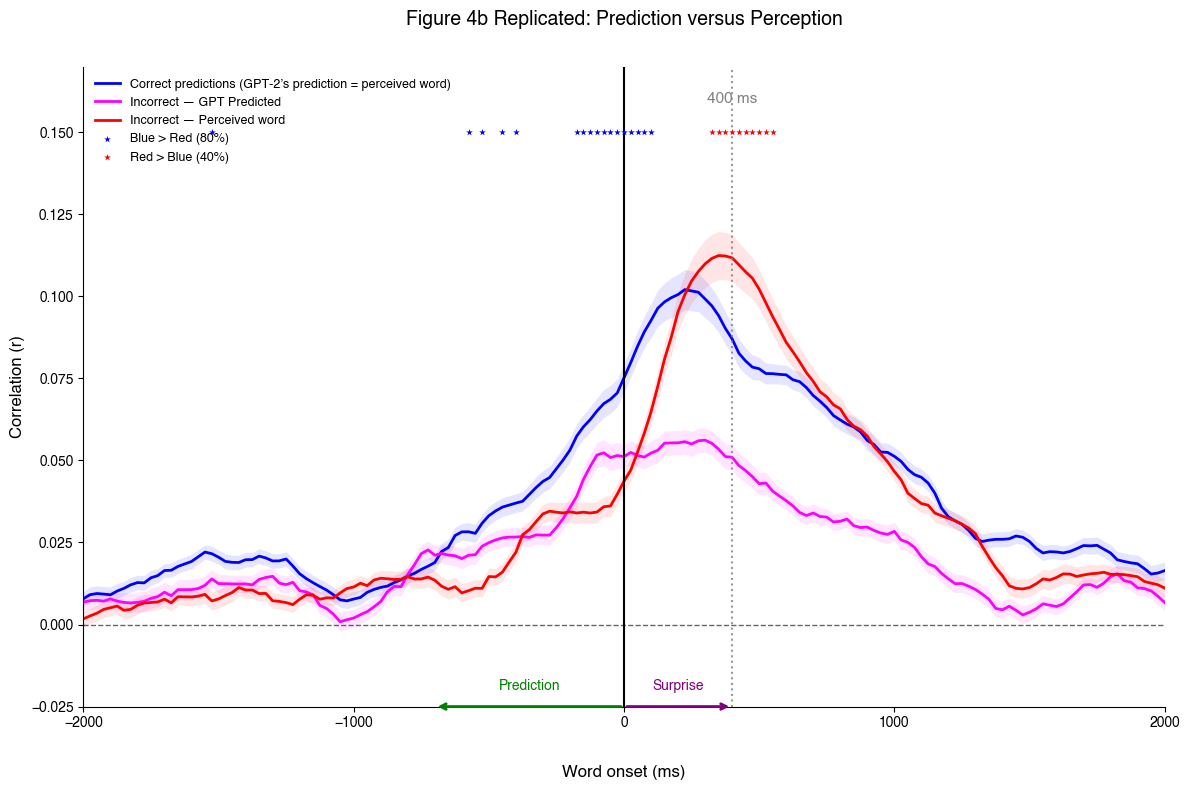

In [96]:
#Re-loading the results above so this figure will always show up (no need to re-run/spend compute)
results_dir = "results_figure4b"
subject_ids = ["02", "03", "04", "05", "06", "07", "08", "09"]
lags_ms = np.linspace(-2000, 2000, 161)

# 2. LOADING LOGIC
all_corrs_correct = []
all_corrs_prediction = []
all_corrs_perceived = []

print("Checking for saved correlation files...")
for sid in subject_ids:
    f_corr = os.path.join(results_dir, f"corrs_4b_correct_{sid}.npy")
    f_pred = os.path.join(results_dir, f"corrs_4b_prediction_{sid}.npy")
    f_perc = os.path.join(results_dir, f"corrs_4b_perceived_{sid}.npy")
    
    if os.path.exists(f_corr) and os.path.exists(f_pred) and os.path.exists(f_perc):
        all_corrs_correct.append(np.load(f_corr).mean(axis=0))
        all_corrs_prediction.append(np.load(f_pred).mean(axis=0))
        all_corrs_perceived.append(np.load(f_perc).mean(axis=0))

if not all_corrs_correct:
    raise FileNotFoundError("No correlation files found.")

r_blue = np.concatenate(all_corrs_correct, axis=0)    
r_mag  = np.concatenate(all_corrs_prediction, axis=0) 
r_red  = np.concatenate(all_corrs_perceived, axis=0)  
n_elec = r_blue.shape[0]

# Significance Testing (custom thresholds) for asterisks
def run_significance_test(diff_data, threshold, n_perms=5000):
    """
    Performs a one-tailed permutation test (diff > 0) per timepoint.
    """
    n_elec_total, n_times = diff_data.shape
    actual_mean = diff_data.mean(axis=0)
    pct_pos = (diff_data > 0).mean(axis=0)

    rng = np.random.default_rng(seed=0)
    signs = rng.choice(np.array([-1, 1], dtype=np.float32), size=(n_perms, n_elec_total, 1))
    null_dist = (signs * diff_data[np.newaxis, :, :]).mean(axis=1)

    p_vals = np.array([(null_dist[:, t] >= actual_mean[t]).mean() for t in range(n_times)])
    sig_fdr, _ = fdrcorrection(p_vals, alpha=0.01)
    
    return sig_fdr & (pct_pos >= threshold)

# Red > Blue
sig_red = run_significance_test(r_red - r_blue, threshold=0.40)

# Mag > Blue
sig_mag = run_significance_test(r_mag - r_blue, threshold=0.00)

# Blue > Red
sig_blue_vs_red = run_significance_test(r_blue - r_red, threshold=0.67)

# PLOTTING
def make_replicated_plot_4b():
    mean_b = r_blue.mean(axis=0); se_b = r_blue.std(axis=0)/np.sqrt(n_elec)
    mean_m = r_mag.mean(axis=0);  se_m = r_mag.std(axis=0)/np.sqrt(n_elec)
    mean_r = r_red.mean(axis=0);  se_r = r_red.std(axis=0)/np.sqrt(n_elec)

    plt.rcParams['font.sans-serif'] = ['Helvetica', 'Arial']
    fig, ax = plt.subplots(figsize=(12, 8))

    # Curves
    ax.fill_between(lags_ms, mean_b - se_b, mean_b + se_b, color='blue', alpha=0.1, lw=0)
    ax.plot(lags_ms, mean_b, color='blue', lw=2, label='Correct predictions (GPT-2’s prediction = perceived word)')

    ax.fill_between(lags_ms, mean_m - se_m, mean_m + se_m, color='magenta', alpha=0.1, lw=0)
    ax.plot(lags_ms, mean_m, color='magenta', lw=2, label='Incorrect — GPT Predicted')

    ax.fill_between(lags_ms, mean_r - se_r, mean_r + se_r, color='red', alpha=0.1, lw=0)
    ax.plot(lags_ms, mean_r, color='red', lw=2, label='Incorrect — Perceived word')

    # AXIS LIMITS
    y_min = -0.025
    y_max = 0.17
    ax.set_ylim(y_min, y_max)
    
    # SIGNIFICANCE MARKERS (All on the same horizontal line)
    star_y = 0.15
    
    # We plot them in order so colors don't completely mask each other if they overlap
    if sig_mag.any():
        ax.scatter(lags_ms[sig_mag], np.full(sig_mag.sum(), star_y),
                   marker="*", s=25, color="magenta", linewidths=0, zorder=5, label='Mag > Blue (63%)')
    
    if sig_blue_vs_red.any():
        ax.scatter(lags_ms[sig_blue_vs_red], np.full(sig_blue_vs_red.sum(), star_y),
                   marker="*", s=25, color="blue", linewidths=0, zorder=6, label='Blue > Red (80%)')

    if sig_red.any():
        ax.scatter(lags_ms[sig_red], np.full(sig_red.sum(), star_y),
                   marker="*", s=25, color="red", linewidths=0, zorder=7, label='Red > Blue (40%)')

    # Dotted line at 400 ms and Label
    ax.axvline(400, color="grey", lw=1.5, ls=":", alpha=0.8)
    ax.text(400, star_y + 0.008, "400 ms", ha='center', va='bottom', fontsize=11, color='grey')

    # Dotted Baseline and Word onset Line
    ax.axhline(0, color="black", lw=1.0, ls="--", alpha=0.6)
    ax.axvline(0, color="black", lw=1.5)

    # Floor spine
    ax.spines['bottom'].set_position(('data', y_min))
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    
    # --- ARROWS ---
    # Green Prediction Arrow
    ax.annotate('', xy=(-700, y_min), xytext=(0, y_min),
                arrowprops=dict(arrowstyle='->', color='green', lw=2))
    ax.text(-350, y_min + 0.005, "Prediction", color="green", style="italic", ha="center", fontweight='bold')

    # Purple Surprise Arrow
    ax.annotate('', xy=(400, y_min), xytext=(0, y_min),
                arrowprops=dict(arrowstyle='->', color='purple', lw=2))
    ax.text(200, y_min + 0.005, "Surprise", color="purple", style="italic", ha="center", fontweight='bold')

    ax.set_xlim(-2000, 2000)
    ax.set_xticks([-2000, -1000, 0, 1000, 2000])
    ax.set_xlabel("Word onset (ms)", fontsize=12, labelpad=25)
    ax.set_ylabel("Correlation (r)", fontsize=12)
    ax.set_title("Figure 4b Replicated: Prediction versus Perception", fontsize=14, pad=30)

    ax.legend(loc="upper left", frameon=False, fontsize=9)
    plt.tight_layout()
    plt.savefig("Figure_4B.png", dpi=400)
    plt.savefig("Figure_4B.pdf", format='pdf', bbox_inches='tight')
    plt.show()

make_replicated_plot_4b()